
# Notebook 04 - Geo Incrementality Experiment vs. Baseline MMM

## Northstar Hydration

Notebook 03 gave us a well-fitting **observational MMM**.

It explained historical sales reasonably well and produced channel response curves, but one question remained:

> **Are the media effects estimated from historical data actually causal?**

This notebook creates a controlled **Paid Social geo experiment** and compares:

1. the causal lift estimated from the experiment;
2. the incremental lift predicted by the baseline MMM for the same spend intervention;
3. the hidden causal truth that we know only because this is simulated data.

---

## Business question

Northstar is considering increasing Paid Social investment.

The experiment asks:

> **What happens to unit sales if Paid Social spend is increased by 40% in a selected group of markets for 8 weeks?**

We will use a matched-pair geo design:

- pair similar markets using pre-test behavior;
- randomly assign one market in each pair to treatment;
- leave the paired market as control;
- increase Paid Social only in treatment markets;
- estimate incremental units with a matched-pair difference-in-differences approach.

---

## Why this matters

A strong historical model can still attribute media incorrectly.

The MMM has to infer causality from observational variation.

The experiment directly creates variation:

\[
Treatment = \text{same business environment} + \text{intentional Social spend increase}
\]

That gives us a causal benchmark for the MMM.


## 1. Setup

In [ ]:
%pip install -q -U pymc-marketing arviz

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.7/42.7 kB 884.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 771.1/771.1 kB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.3/253.3 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.4/209.4 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 527.7/527.7 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.3/608.3 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 388.2/388.2 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.1/41.1 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 30.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 27.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.2/69.2 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.

In [ ]:

from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az

from pymc_marketing.mmm import MMM

SEED = 42
EXPERIMENT_SEED = 2026
rng = np.random.default_rng(EXPERIMENT_SEED)

USE_GOOGLE_DRIVE = True

if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_DIR = Path("/content/drive/MyDrive/northstar_cpg")
    except ImportError:
        PROJECT_DIR = Path("/mnt/data/northstar_cpg")
else:
    PROJECT_DIR = Path("/mnt/data/northstar_cpg")

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = PROJECT_DIR / "models"

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODELING_PATH = DATA_DIR / "northstar_modeling_data.csv"
TRUTH_PATH = DATA_DIR / "northstar_simulation_truth.csv"
PARAMS_PATH = DATA_DIR / "northstar_true_parameters.json"
MODEL_PATH = MODEL_DIR / "northstar_baseline_mmm.nc"

print("Project:", PROJECT_DIR)
print("Baseline model:", MODEL_PATH)


Mounted at /content/drive
Project: /content/drive/MyDrive/northstar_cpg
Baseline model: /content/drive/MyDrive/northstar_cpg/models/northstar_baseline_mmm.nc



Notebook 04 needs the outputs created earlier:

- `northstar_modeling_data.csv` from Notebook 01;
- `northstar_simulation_truth.csv` from Notebook 01;
- `northstar_true_parameters.json` from Notebook 01;
- `northstar_baseline_mmm.nc` from Notebook 03.

If the `.nc` model file is missing, rerun the final save-model cell in Notebook 03.


## 2. Load the observed data and hidden simulation truth

In [ ]:

required_files = [
    MODELING_PATH,
    TRUTH_PATH,
    PARAMS_PATH,
    MODEL_PATH,
]

missing = [str(path) for path in required_files if not path.exists()]

if missing:
    raise FileNotFoundError(
        "The following required files are missing:\n"
        + "\n".join(missing)
    )

df = pd.read_csv(MODELING_PATH, parse_dates=["week"])
simulation_truth = pd.read_csv(TRUTH_PATH, parse_dates=["week"])

with open(PARAMS_PATH, "r") as f:
    TRUE_PARAMS = json.load(f)

print("Observed data:", df.shape)
print("Simulation truth:", simulation_truth.shape)


Observed data: (2080, 24)
Simulation truth: (2080, 39)



### Important separation

`df` is the dataset an analyst could realistically observe.

`simulation_truth` contains hidden variables that do **not** exist in a normal business dataset.

We use hidden truth only to **simulate the experiment** and later validate the result.

The experiment analysis itself will use only the observed experimental outcomes.


## 3. Define the pre-test and test windows

In [ ]:

all_weeks = np.sort(df["week"].unique())

TEST_WEEKS = pd.to_datetime(all_weeks[-8:])
PRE_WEEKS = pd.to_datetime(all_weeks[-20:-8])

TEST_START = TEST_WEEKS.min()
TEST_END = TEST_WEEKS.max()

print("Pre-period:", PRE_WEEKS.min().date(), "to", PRE_WEEKS.max().date())
print("Test-period:", TEST_START.date(), "to", TEST_END.date())
print("Pre weeks:", len(PRE_WEEKS))
print("Test weeks:", len(TEST_WEEKS))


Pre-period: 2025-08-11 to 2025-10-27
Test-period: 2025-11-03 to 2025-12-22
Pre weeks: 12
Test weeks: 8



We use:

- **12 weeks pre-test** to match markets and measure baseline differences;
- **8 weeks test** for the Paid Social intervention.

Because the test is simulated, we can deliberately choose a clean window at the end of the historical period.


## 4. Build pre-test market profiles

In [ ]:

pre_profiles = (
    df[df["week"].isin(PRE_WEEKS)]
    .groupby("market", as_index=True)
    .agg(
        avg_units=("units", "mean"),
        avg_social_spend=("social_spend", "mean"),
        avg_price=("actual_price", "mean"),
        avg_distribution=("distribution", "mean"),
    )
)

pre_profiles.head()


,avg_units,avg_social_spend,avg_price,avg_distribution
market,,,,
Atlanta,38114.000000,6315.988696,10.375700,0.771978
Boston,31059.583333,5379.413492,10.116805,0.864524
Charlotte,46742.166667,7096.085151,10.207840,0.833701
Chicago,32822.166667,4420.036620,10.409200,0.744713
Dallas,25234.166667,3108.458459,10.274650,0.862669



We want paired markets to look similar **before the experiment**.

The matching variables are:

- average units;
- average Paid Social spend;
- average shelf price;
- average distribution.

This makes it less likely that we compare a huge, heavily distributed market with a much smaller one.


## 5. Standardize matching variables

In [ ]:

matching_z = (
    pre_profiles - pre_profiles.mean()
) / pre_profiles.std()

matching_z.head()


,avg_units,avg_social_spend,avg_price,avg_distribution
market,,,,
Atlanta,1.037264,0.776808,0.843784,-0.215197
Boston,-0.104688,0.084658,-0.496077,1.190944
Charlotte,2.433970,1.353317,-0.024945,0.722620
Chicago,0.180635,-0.624343,1.017158,-0.629464
Dallas,-1.047691,-1.593629,0.320818,1.162768



We standardize because the variables use very different units.

For example:

- sales may be tens of thousands of units;
- price is around $10;
- distribution is around 0.7.

After standardization, each variable is measured in standard-deviation units, so no single large-scale variable dominates the distance calculation.


## 6. Pair similar markets

In [ ]:

def greedy_match_markets(z_df):
    remaining = list(z_df.sort_index().index)
    pairs = []

    while remaining:
        market_a = remaining.pop(0)

        candidate_data = z_df.loc[remaining]
        distance = np.sqrt(
            ((candidate_data - z_df.loc[market_a]) ** 2).sum(axis=1)
        )

        market_b = distance.idxmin()
        pair_distance = float(distance.loc[market_b])

        remaining.remove(market_b)

        pairs.append(
            {
                "market_a": market_a,
                "market_b": market_b,
                "match_distance": pair_distance,
            }
        )

    return pd.DataFrame(pairs)


matched_pairs = greedy_match_markets(matching_z)
matched_pairs


,market_a,market_b,match_distance
0,Atlanta,Detroit,1.069777
1,Boston,Philadelphia,0.592236
2,Charlotte,Denver,1.414958
3,Chicago,Minneapolis,0.943259
4,Dallas,Phoenix,1.724348
5,Houston,San Diego,1.165216
6,Los Angeles,San Francisco,1.059057
7,Miami,Seattle,1.110825
8,Nashville,Washington DC,1.793008
9,New York,Orlando,2.045017



`match_distance` is a summary of how different the two markets were across the standardized matching variables.

Smaller values mean a closer match.

This is a simple greedy matching algorithm rather than a production-grade experimental design optimizer, but it is sufficient for our simulated use case.


## 7. Randomize treatment within each matched pair

In [ ]:

assignment_rng = np.random.default_rng(EXPERIMENT_SEED)

assignments = []

for pair_id, row in matched_pairs.reset_index(drop=True).iterrows():
    pair_markets = [row["market_a"], row["market_b"]]

    treatment_market = assignment_rng.choice(pair_markets)
    control_market = (
        pair_markets[1]
        if treatment_market == pair_markets[0]
        else pair_markets[0]
    )

    assignments.append(
        {
            "pair_id": pair_id + 1,
            "treatment_market": treatment_market,
            "control_market": control_market,
            "match_distance": row["match_distance"],
        }
    )

assignment_table = pd.DataFrame(assignments)

assignment_table


,pair_id,treatment_market,control_market,match_distance
0,1,Detroit,Atlanta,1.069777
1,2,Boston,Philadelphia,0.592236
2,3,Charlotte,Denver,1.414958
3,4,Minneapolis,Chicago,0.943259
4,5,Dallas,Phoenix,1.724348
5,6,Houston,San Diego,1.165216
6,7,Los Angeles,San Francisco,1.059057
7,8,Miami,Seattle,1.110825
8,9,Washington DC,Nashville,1.793008
9,10,New York,Orlando,2.045017



The important causal-design step is **randomization within matched pairs**.

Matching improves comparability.

Randomization prevents us from deliberately choosing the stronger-looking market as treatment.


In [ ]:

market_assignment = pd.concat(
    [
        assignment_table[
            ["pair_id", "treatment_market"]
        ].rename(columns={"treatment_market": "market"}).assign(group="treatment"),

        assignment_table[
            ["pair_id", "control_market"]
        ].rename(columns={"control_market": "market"}).assign(group="control"),
    ],
    ignore_index=True,
)

market_assignment.sort_values(["pair_id", "group"])


,pair_id,market,group
10,1,Atlanta,control
0,1,Detroit,treatment
11,2,Philadelphia,control
1,2,Boston,treatment
12,3,Denver,control
2,3,Charlotte,treatment
13,4,Chicago,control
3,4,Minneapolis,treatment
14,5,Phoenix,control
4,5,Dallas,treatment


## 8. Inspect pre-test balance

In [ ]:

balance = (
    pre_profiles.reset_index()
    .merge(market_assignment, on="market", how="left")
    .groupby("group")
    .agg(
        avg_units=("avg_units", "mean"),
        avg_social_spend=("avg_social_spend", "mean"),
        avg_price=("avg_price", "mean"),
        avg_distribution=("avg_distribution", "mean"),
    )
)

balance


,avg_units,avg_social_spend,avg_price,avg_distribution
group,,,,
control,32136.350000,5301.512509,10.257360,0.785234
treatment,31276.233333,5228.206018,10.167959,0.787049



Treatment and control do not need to be numerically identical.

The goal is that they are reasonably comparable **before** the test.

The matched-pair difference-in-differences estimator will also account for persistent pair-level differences.


## 9. Define the Paid Social intervention

In [ ]:

SOCIAL_LIFT_FACTOR = 1.40

print(
    f"Treatment markets will receive a "
    f"{(SOCIAL_LIFT_FACTOR - 1) * 100:.0f}% increase in Paid Social spend."
)


Treatment markets will receive a 40% increase in Paid Social spend.



We use a **40% spend increase**.

This is intentionally large enough to create a measurable signal in an 8-week simulated test while remaining easy to interpret.

Only treatment markets receive the increase.


## 10. Helper functions from the hidden data-generating process

In [ ]:

def geometric_adstock(x, alpha):
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x, dtype=float)

    for i, value in enumerate(x):
        out[i] = (
            value
            if i == 0
            else value + alpha * out[i - 1]
        )

    return out


def saturation(x, half_saturation):
    x = np.asarray(x, dtype=float)
    return x / (x + half_saturation)



These are the same hidden transformations used when Notebook 01 generated the synthetic world.

A real analyst would **not** know the true parameters.

We use them only because we need a simulated experiment with a known causal effect.


## 11. Simulate the geo experiment

In [ ]:

experiment_truth = (
    simulation_truth
    .merge(market_assignment, on="market", how="left")
    .sort_values(["market", "week"])
    .reset_index(drop=True)
)

experiment_truth["experiment_social_spend"] = (
    experiment_truth["social_spend"].copy()
)

treatment_test_mask = (
    (experiment_truth["group"] == "treatment")
    & (experiment_truth["week"].isin(TEST_WEEKS))
)

experiment_truth.loc[
    treatment_test_mask,
    "experiment_social_spend"
] *= SOCIAL_LIFT_FACTOR



The intervention changes **only Paid Social spend**.

Price, promotion, CTV, Search, Retail Media, distribution, competitor price, seasonality, and latent demand remain unchanged.

That is what makes the experiment interpretable.


In [ ]:

social_params = TRUE_PARAMS["channels"]["social"]

experiment_truth["experiment_social_adstock"] = (
    experiment_truth
    .groupby("market", sort=False)["experiment_social_spend"]
    .transform(
        lambda s: geometric_adstock(
            s.to_numpy(),
            social_params["adstock_alpha"],
        )
    )
)

experiment_truth["experiment_social_saturation"] = saturation(
    experiment_truth["experiment_social_adstock"].to_numpy(),
    social_params["half_saturation_spend"],
)

experiment_truth["delta_social_log_effect"] = (
    social_params["max_log_demand_lift"]
    * (
        experiment_truth["experiment_social_saturation"]
        - experiment_truth["true_social_saturation"]
    )
)



The experiment changes Social spend, which changes:

\[
Spend
ightarrow Adstock
ightarrow Saturation
ightarrow Demand
\]

We compute only the **difference in the true Social effect**.

Everything else is held fixed.


## 12. Generate potential outcomes

In [ ]:

experiment_noise = np.zeros(len(experiment_truth))

test_mask = experiment_truth["week"].isin(TEST_WEEKS)

experiment_noise[test_mask] = rng.normal(
    loc=0,
    scale=0.015,
    size=test_mask.sum(),
)

experiment_truth["potential_units_control"] = (
    experiment_truth["units"]
    * np.exp(experiment_noise)
)

experiment_truth["potential_units_treatment"] = (
    experiment_truth["potential_units_control"]
    * np.exp(experiment_truth["delta_social_log_effect"])
)

experiment_truth["experiment_units"] = (
    experiment_truth["potential_units_control"].copy()
)

experiment_truth.loc[
    treatment_test_mask,
    "experiment_units"
] = experiment_truth.loc[
    treatment_test_mask,
    "potential_units_treatment"
]

experiment_truth["experiment_units"] = (
    experiment_truth["experiment_units"].round().astype(int)
)



### Potential-outcomes interpretation

For every treatment observation we can simulate:

- what units would have been **without** the Social increase;
- what units would have been **with** the Social increase.

In a real experiment we would observe only one of these.

That unobserved alternative is the counterfactual.

Synthetic data gives us the luxury of knowing both — but we will hide that information from the experiment estimator.


In [ ]:

experiment_truth["true_incremental_units"] = 0.0

experiment_truth.loc[
    treatment_test_mask,
    "true_incremental_units"
] = (
    experiment_truth.loc[
        treatment_test_mask,
        "potential_units_treatment"
    ]
    - experiment_truth.loc[
        treatment_test_mask,
        "potential_units_control"
    ]
)


## 13. Create the analyst-facing experiment dataset

In [ ]:

experiment_cols = [
    "week",
    "market",
    "pair_id",
    "group",
    "experiment_units",
    "social_spend",
    "experiment_social_spend",
    "actual_price",
    "promo_depth",
    "competitor_price",
    "distribution",
    "ctv_spend",
    "retail_media_spend",
    "search_spend",
]

experiment_df = experiment_truth[experiment_cols].copy()

experiment_df["period"] = np.select(
    [
        experiment_df["week"].isin(PRE_WEEKS),
        experiment_df["week"].isin(TEST_WEEKS),
    ],
    [
        "pre",
        "test",
    ],
    default="other",
)

experiment_df.head()


,week,market,pair_id,group,experiment_units,social_spend,experiment_social_spend,actual_price,promo_depth,competitor_price,distribution,ctv_spend,retail_media_spend,search_spend,period
0,2024-01-01,Atlanta,1,control,23663,3903.727442,3903.727442,10.201559,0.0,9.634526,0.692153,0.0,4221.852802,1625.441045,other
1,2024-01-08,Atlanta,1,control,25647,4897.625941,4897.625941,9.181403,0.1,9.662154,0.681406,0.0,6026.109381,2702.966512,other
2,2024-01-15,Atlanta,1,control,22100,4205.357553,4205.357553,10.201559,0.0,9.484917,0.712312,0.0,1848.820653,1665.083923,other
3,2024-01-22,Atlanta,1,control,25813,1565.614812,1565.614812,10.201559,0.0,9.404369,0.690642,0.0,10395.039777,2955.894222,other
4,2024-01-29,Atlanta,1,control,21226,4086.024155,4086.024155,10.201559,0.0,9.453595,0.666450,0.0,2697.650070,866.299137,other



From here through the experimental analysis, pretend this is all we know.

The hidden true causal effect is **not** included.


## 14. Visualize treatment and control trends

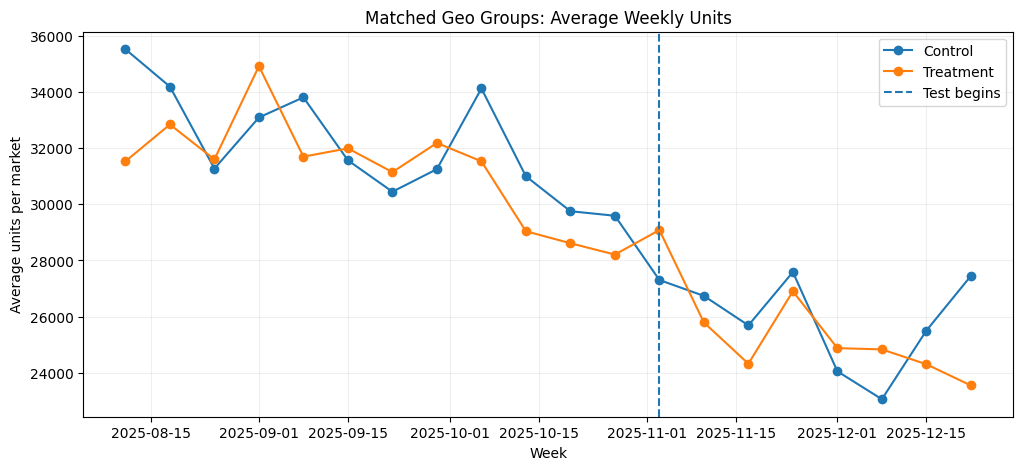

In [ ]:

weekly_groups = (
    experiment_df[
        experiment_df["week"].isin(
            np.concatenate([PRE_WEEKS, TEST_WEEKS])
        )
    ]
    .groupby(["week", "group"], as_index=False)
    .agg(
        avg_units=("experiment_units", "mean"),
        avg_social_spend=("experiment_social_spend", "mean"),
    )
)

fig, ax = plt.subplots(figsize=(12, 5))

for group, group_data in weekly_groups.groupby("group"):
    ax.plot(
        group_data["week"],
        group_data["avg_units"],
        marker="o",
        label=group.title(),
    )

ax.axvline(
    TEST_START,
    linestyle="--",
    linewidth=1.5,
    label="Test begins",
)

ax.set_title("Matched Geo Groups: Average Weekly Units")
ax.set_xlabel("Week")
ax.set_ylabel("Average units per market")
ax.legend()
ax.grid(alpha=0.2)

plt.show()



Before the test begins, treatment and control trends should look reasonably similar.

Once the test starts, a systematic widening between the groups may indicate incremental lift.

But visual inspection alone is not enough — we estimate the effect formally next.


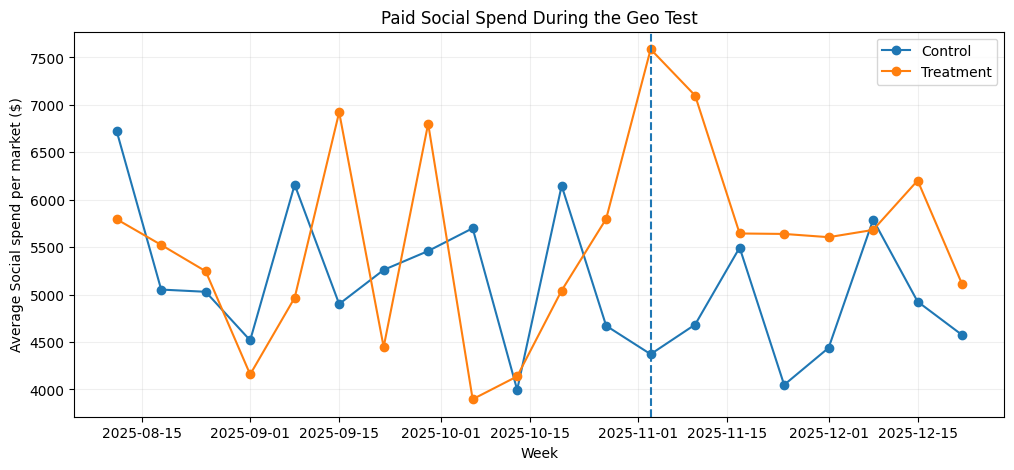

In [ ]:

fig, ax = plt.subplots(figsize=(12, 5))

for group, group_data in weekly_groups.groupby("group"):
    ax.plot(
        group_data["week"],
        group_data["avg_social_spend"],
        marker="o",
        label=group.title(),
    )

ax.axvline(TEST_START, linestyle="--", linewidth=1.5)

ax.set_title("Paid Social Spend During the Geo Test")
ax.set_xlabel("Week")
ax.set_ylabel("Average Social spend per market ($)")
ax.legend()
ax.grid(alpha=0.2)

plt.show()


## 15. Matched-pair difference-in-differences


For each matched pair, calculate:

\[
\text{Pair Difference}_t
=
Units_{Treatment,t}
-
Units_{Control,t}
\]

Then compare the average pair difference during the test with the average difference before the test:

\[
Lift_{pair}
=
\overline{Difference}_{test}
-
\overline{Difference}_{pre}
\]

This removes persistent treatment-control differences within each matched pair.


In [ ]:

analysis_window = experiment_df[
    experiment_df["period"].isin(["pre", "test"])
].copy()

pair_week = (
    analysis_window
    .pivot_table(
        index=["pair_id", "week", "period"],
        columns="group",
        values="experiment_units",
        aggfunc="mean",
    )
    .reset_index()
)

pair_week["treatment_minus_control"] = (
    pair_week["treatment"] - pair_week["control"]
)

pair_period = (
    pair_week
    .groupby(["pair_id", "period"], as_index=False)
    .agg(
        avg_pair_difference=("treatment_minus_control", "mean")
    )
)

pair_period_wide = (
    pair_period
    .pivot(
        index="pair_id",
        columns="period",
        values="avg_pair_difference",
    )
    .reset_index()
)

pair_period_wide["incremental_units_per_week"] = (
    pair_period_wide["test"]
    - pair_period_wide["pre"]
)

pair_period_wide


period,pair_id,pre,test,incremental_units_per_week
0,1,-4964.000000,374.375,5338.375000
1,2,361.083333,2376.250,2015.166667
2,3,5311.500000,4527.375,-784.125000
3,4,-4662.583333,-10129.375,-5466.791667
4,5,-204.166667,-2499.125,-2294.958333
5,6,4954.166667,4520.000,-434.166667
6,7,3585.666667,1284.750,-2300.916667
7,8,-3764.250000,2348.500,6112.750000
8,9,-6429.000000,-8586.125,-2157.125000
9,10,-2789.583333,1132.250,3921.833333


## 16. Estimate total incremental units

In [ ]:

N_TEST_WEEKS = len(TEST_WEEKS)

experiment_total_lift = (
    pair_period_wide["incremental_units_per_week"].sum()
    * N_TEST_WEEKS
)

incremental_social_spend = (
    experiment_df.loc[
        treatment_test_mask,
        "experiment_social_spend"
    ].sum()
    - experiment_df.loc[
        treatment_test_mask,
        "social_spend"
    ].sum()
)

incremental_units_per_1000 = (
    experiment_total_lift
    / incremental_social_spend
    * 1_000
)

print(f"Estimated total incremental units: {experiment_total_lift:,.0f}")
print(f"Incremental Social spend: ${incremental_social_spend:,.0f}")
print(
    f"Estimated incremental units per $1,000 spend: "
    f"{incremental_units_per_1000:,.1f}"
)


Estimated total incremental units: 31,600
Incremental Social spend: $138,761
Estimated incremental units per $1,000 spend: 227.7



This is the core experimental estimate.

We are keeping the outcome in **units**, because the baseline MMM was also modeled on units.

Later pricing/profit notebooks can translate units into revenue and contribution margin.


## 17. Bootstrap uncertainty across matched pairs

In [ ]:

BOOTSTRAP_DRAWS = 5_000
bootstrap_rng = np.random.default_rng(EXPERIMENT_SEED + 1)

pair_lifts = (
    pair_period_wide["incremental_units_per_week"]
    .to_numpy()
)

bootstrap_total_lifts = np.empty(BOOTSTRAP_DRAWS)

for i in range(BOOTSTRAP_DRAWS):
    sampled_pair_lifts = bootstrap_rng.choice(
        pair_lifts,
        size=len(pair_lifts),
        replace=True,
    )

    bootstrap_total_lifts[i] = (
        sampled_pair_lifts.sum()
        * N_TEST_WEEKS
    )

experiment_ci_low, experiment_ci_high = np.quantile(
    bootstrap_total_lifts,
    [0.025, 0.975],
)

print(
    f"Experiment lift: {experiment_total_lift:,.0f} units"
)
print(
    f"95% bootstrap interval: "
    f"[{experiment_ci_low:,.0f}, {experiment_ci_high:,.0f}]"
)


Experiment lift: 31,600 units
95% bootstrap interval: [-143,734, 207,554]



Bootstrapping repeatedly resamples the matched pairs.

This asks:

> If we had sampled a somewhat different set of comparable geo pairs, how much might our lift estimate change?

The resulting interval represents experimental uncertainty.


## 18. Load the fitted baseline MMM

In [ ]:

mmm = MMM.load(MODEL_PATH)

print("Loaded baseline MMM.")
print("Channels:", mmm.channel_columns)
print("Controls:", mmm.control_columns)


Loaded baseline MMM.
Channels: ['ctv_spend', 'social_spend', 'retail_media_spend', 'search_spend']
Controls: ['avg_actual_price', 'promo_share', 'avg_competitor_price', 'avg_distribution', 'summer_event']



We are **not refitting** the MMM using the experimental result.

At this stage we want an honest comparison:

> What would the observational MMM have predicted before being told the experiment result?


## 19. Rebuild the national MMM feature table

In [ ]:

weekly = (
    df.groupby("week", as_index=False)
      .agg(
          total_units=("units", "sum"),

          ctv_spend=("ctv_spend", "sum"),
          social_spend=("social_spend", "sum"),
          retail_media_spend=("retail_media_spend", "sum"),
          search_spend=("search_spend", "sum"),

          avg_actual_price=("actual_price", "mean"),
          promo_share=("promo_flag", "mean"),
          avg_competitor_price=("competitor_price", "mean"),
          avg_distribution=("distribution", "mean"),
          summer_event=("summer_event", "max"),
      )
      .sort_values("week")
      .reset_index(drop=True)
)

controls_to_standardize = [
    "avg_actual_price",
    "promo_share",
    "avg_competitor_price",
    "avg_distribution",
]

for col in controls_to_standardize:
    weekly[f"{col}_z"] = (
        weekly[col] - weekly[col].mean()
    ) / weekly[col].std()

CHANNEL_COLUMNS = [
    "ctv_spend",
    "social_spend",
    "retail_media_spend",
    "search_spend",
]

CONTROL_COLUMNS = [
    "avg_actual_price_z",
    "promo_share_z",
    "avg_competitor_price_z",
    "avg_distribution_z",
    "summer_event",
]

FEATURE_COLUMNS = [
    "week",
    *CHANNEL_COLUMNS,
    *CONTROL_COLUMNS,
]

X_factual = weekly[FEATURE_COLUMNS].copy()



This recreates the exact feature structure used in Notebook 03.

## 20. Create the MMM intervention scenario

In [ ]:

extra_social_by_week = (
    experiment_df[
        (experiment_df["group"] == "treatment")
        & (experiment_df["week"].isin(TEST_WEEKS))
    ]
    .assign(
        incremental_social_spend=lambda d:
            d["experiment_social_spend"] - d["social_spend"]
    )
    .groupby("week")["incremental_social_spend"]
    .sum()
)

X_intervention = X_factual.copy()

X_intervention["social_spend"] = (
    X_intervention["social_spend"]
    + X_intervention["week"]
      .map(extra_social_by_week)
      .fillna(0)
)

comparison_spend = X_factual[
    ["week", "social_spend"]
].rename(
    columns={"social_spend": "factual_social_spend"}
).merge(
    X_intervention[
        ["week", "social_spend"]
    ].rename(
        columns={"social_spend": "intervention_social_spend"}
    ),
    on="week",
)

comparison_spend[
    comparison_spend["week"].isin(TEST_WEEKS)
]


,week,factual_social_spend,intervention_social_spend
96,2025-11-03,97908.034272,119582.821452
97,2025-11-10,97540.449229,117819.514730
98,2025-11-17,95271.444606,111397.856475
99,2025-11-24,80769.158576,96881.885126
100,2025-12-01,84429.689546,100444.881157
101,2025-12-08,98478.519462,114712.406457
102,2025-12-15,93563.422982,111284.403947
103,2025-12-22,82237.731030,96836.022958



The national MMM does not know which individual markets were treated.

So we translate the geo experiment into its **national spend equivalent**:

> original national Social spend  
> + the incremental Social dollars added across treatment markets.

All other national features remain unchanged.


## 21. Ask the MMM for the incremental Social lift

In [ ]:

PREDICTION_SEED = 99

factual_pp = mmm.sample_posterior_predictive(
    X=X_factual,
    extend_idata=False,
    combined=True,
    var_names=["channel_contribution_original_scale"],
    random_seed=PREDICTION_SEED,
)

intervention_pp = mmm.sample_posterior_predictive(
    X=X_intervention,
    extend_idata=False,
    combined=True,
    var_names=["channel_contribution_original_scale"],
    random_seed=PREDICTION_SEED,
)

factual_social = (
    factual_pp["channel_contribution_original_scale"]
    .sel(channel="social_spend")
    .sel(date=TEST_WEEKS)
)

intervention_social = (
    intervention_pp["channel_contribution_original_scale"]
    .sel(channel="social_spend")
    .sel(date=TEST_WEEKS)
)

mmm_lift_samples = (
    intervention_social - factual_social
).sum(dim="date")

mmm_lift_values = np.asarray(mmm_lift_samples).reshape(-1)

mmm_lift_median = np.median(mmm_lift_values)
mmm_ci_low, mmm_ci_high = np.quantile(
    mmm_lift_values,
    [0.025, 0.975],
)

print(
    f"MMM-predicted incremental units: "
    f"{mmm_lift_median:,.0f}"
)
print(
    f"95% posterior interval: "
    f"[{mmm_ci_low:,.0f}, {mmm_ci_high:,.0f}]"
)


Output()

Output()

MMM-predicted incremental units: 6,195
95% posterior interval: [265, 27,121]



This is the direct comparison we wanted.

The MMM sees exactly the same additional national Social spend created by the geo test and asks:

> According to my learned response curve, how many extra units should that spend create?

Because we use `channel_contribution_original_scale`, this comparison focuses on the modeled change in Social contribution rather than adding new observation noise.


## 22. Compare MMM vs. experiment

In [ ]:

comparison = pd.DataFrame(
    {
        "method": [
            "Geo experiment",
            "Baseline MMM",
        ],
        "incremental_units": [
            experiment_total_lift,
            mmm_lift_median,
        ],
        "lower_95": [
            experiment_ci_low,
            mmm_ci_low,
        ],
        "upper_95": [
            experiment_ci_high,
            mmm_ci_high,
        ],
    }
)

comparison


,method,incremental_units,lower_95,upper_95
0,Geo experiment,31600.333333,-143734.275000,207553.833333
1,Baseline MMM,6194.814800,265.305396,27120.604555


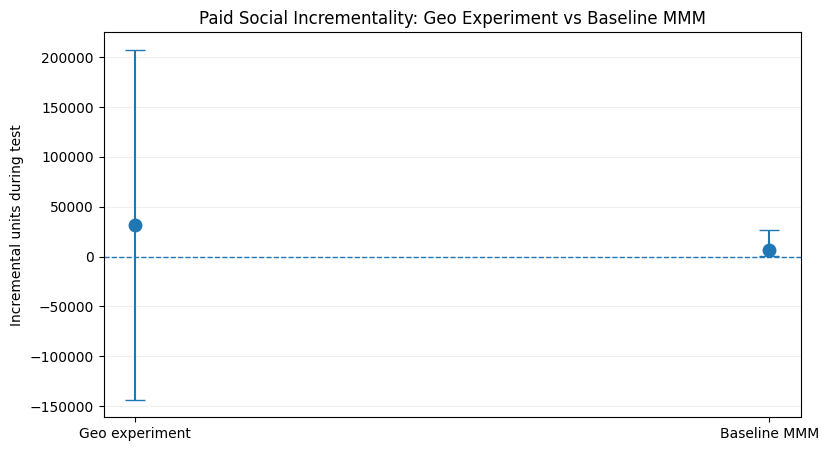

In [ ]:

fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(comparison))

lower_error = (
    comparison["incremental_units"]
    - comparison["lower_95"]
)

upper_error = (
    comparison["upper_95"]
    - comparison["incremental_units"]
)

ax.errorbar(
    x,
    comparison["incremental_units"],
    yerr=np.vstack([lower_error, upper_error]),
    fmt="o",
    capsize=7,
    markersize=9,
)

ax.axhline(0, linestyle="--", linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels(comparison["method"])
ax.set_ylabel("Incremental units during test")
ax.set_title(
    "Paid Social Incrementality: Geo Experiment vs Baseline MMM"
)
ax.grid(axis="y", alpha=0.2)

plt.show()



### How to interpret this plot

There are three possibilities:

1. **Strong agreement**  
   MMM and experiment estimate similar lift.

2. **Directional agreement, magnitude disagreement**  
   Both say Social is incremental, but disagree on how much.

3. **Material disagreement**  
   The experimental result falls well outside what the MMM expected.

Any of these is informative.

The goal is **not** to force disagreement.

The goal is to test the observational model against causal evidence.


## 23. Reveal the hidden causal truth

In [ ]:

true_total_incremental_units = (
    experiment_truth["true_incremental_units"].sum()
)

truth_comparison = comparison.copy()

truth_row = pd.DataFrame(
    {
        "method": ["Hidden simulation truth"],
        "incremental_units": [true_total_incremental_units],
        "lower_95": [true_total_incremental_units],
        "upper_95": [true_total_incremental_units],
    }
)

truth_comparison = pd.concat(
    [truth_comparison, truth_row],
    ignore_index=True,
)

truth_comparison


,method,incremental_units,lower_95,upper_95
0,Geo experiment,31600.333333,-143734.275000,207553.833333
1,Baseline MMM,6194.814800,265.305396,27120.604555
2,Hidden simulation truth,21074.623395,21074.623395,21074.623395



This final row would never exist in a real business analysis.

We include it because synthetic data lets us answer an unusually valuable question:

> Which approach came closer to the true causal effect that generated the experiment?

That makes this project useful for learning, not just presentation.


In [ ]:

experiment_error = abs(
    experiment_total_lift
    - true_total_incremental_units
)

mmm_error = abs(
    mmm_lift_median
    - true_total_incremental_units
)

print(
    f"Hidden true lift: "
    f"{true_total_incremental_units:,.0f} units"
)
print(
    f"Experiment absolute error: "
    f"{experiment_error:,.0f} units"
)
print(
    f"MMM absolute error: "
    f"{mmm_error:,.0f} units"
)


Hidden true lift: 21,075 units
Experiment absolute error: 10,526 units
MMM absolute error: 14,880 units


## 24. Save experiment outputs

In [ ]:

EXPERIMENT_DATA_PATH = (
    DATA_DIR / "northstar_social_geo_experiment.csv"
)

EXPERIMENT_TRUTH_PATH = (
    DATA_DIR / "northstar_social_geo_experiment_truth.csv"
)

PAIR_PATH = (
    OUTPUT_DIR / "geo_experiment_pairs.csv"
)

COMPARISON_PATH = (
    OUTPUT_DIR / "geo_experiment_vs_mmm.csv"
)

experiment_df.to_csv(
    EXPERIMENT_DATA_PATH,
    index=False,
)

experiment_truth[
    [
        "week",
        "market",
        "pair_id",
        "group",
        "potential_units_control",
        "potential_units_treatment",
        "true_incremental_units",
    ]
].to_csv(
    EXPERIMENT_TRUTH_PATH,
    index=False,
)

assignment_table.to_csv(
    PAIR_PATH,
    index=False,
)

truth_comparison.to_csv(
    COMPARISON_PATH,
    index=False,
)

print("Saved:")
print(EXPERIMENT_DATA_PATH)
print(EXPERIMENT_TRUTH_PATH)
print(PAIR_PATH)
print(COMPARISON_PATH)


Saved:
/content/drive/MyDrive/northstar_cpg/data/northstar_social_geo_experiment.csv
/content/drive/MyDrive/northstar_cpg/data/northstar_social_geo_experiment_truth.csv
/content/drive/MyDrive/northstar_cpg/outputs/geo_experiment_pairs.csv
/content/drive/MyDrive/northstar_cpg/outputs/geo_experiment_vs_mmm.csv


## 25. Record the key findings

In [ ]:

summary = {
    "social_spend_increase_pct": (SOCIAL_LIFT_FACTOR - 1) * 100,
    "test_weeks": len(TEST_WEEKS),
    "treatment_markets": (
        market_assignment["group"]
        .eq("treatment")
        .sum()
    ),
    "incremental_social_spend": incremental_social_spend,
    "experiment_incremental_units": experiment_total_lift,
    "experiment_ci_low": experiment_ci_low,
    "experiment_ci_high": experiment_ci_high,
    "mmm_incremental_units": mmm_lift_median,
    "mmm_ci_low": mmm_ci_low,
    "mmm_ci_high": mmm_ci_high,
    "hidden_true_incremental_units": true_total_incremental_units,
}

pd.Series(summary)


,0
social_spend_increase_pct,40.000000
test_weeks,8.000000
treatment_markets,10.000000
incremental_social_spend,138761.342598
experiment_incremental_units,31600.333333
experiment_ci_low,-143734.275000
experiment_ci_high,207553.833333
mmm_incremental_units,6194.814800
mmm_ci_low,265.305396
mmm_ci_high,27120.604555



# Notebook 04 conclusion

We have now moved one step beyond observational MMM.

The workflow is:

\[
Historical\ Data

ightarrow
Baseline\ MMM

ightarrow
Geo\ Experiment

ightarrow
Causal\ Benchmark

ightarrow
MMM\ Comparison
\]

The next question is not:

> Which estimate should we blindly trust?

It is:

> **How should experimental evidence update the MMM?**

That is Notebook 05.

## Next: Notebook 05 — Calibrating MMM With Incrementality Evidence

We will take the lift-test result and use it to inform the Bayesian MMM.

Then we will compare:

- the original Social response curve;
- the experimental lift measurement;
- the calibrated response curve.

That is where MMM and incrementality become one measurement system rather than two separate analyses.
